# Chapter 1 — Introducing Deep Learning: Why You Should Learn It
### Reproduction & Theoretical Deep-Dive — *grokking Deep Learning* (Manning)

This opening chapter of the book is **conceptual**: it motivates the subject and
sets the learning approach rather than implementing anything. So this notebook has two jobs:

1. a written deep-dive on the ideas of the chapter, in my own words;
2. a few **small demos that I added myself** (they are not code from the book) to make the
   abstract ideas concrete: "programs that learn their own rules" and "learning = turning knobs
   to reduce error".

**Roadmap of this notebook**
1. What is deep learning?
2. Where it sits: AI ⊃ Machine Learning ⊃ Deep Learning
3. Why it is worth learning
4. Why build it from scratch with NumPy
5. What you need to know before starting
6. Mental model 1 — learning rules from data (demo)
7. Mental model 2 — knobs and error (demo)
8. Roadmap of Chapters 1–6

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

os.makedirs('outputs', exist_ok=True)
print('NumPy version:', np.__version__)

NumPy version: 2.5.3


## 1. What is deep learning?

**Deep learning** is a family of machine-learning methods built on **artificial neural networks**
that are made of *many layers* of simple computations stacked on top of each other.

Three ideas are packed into that sentence:

- **Simple units.** Each unit (neuron) does something very modest: multiply its inputs by numbers
  called *weights*, add the results, and (usually) pass the sum through a simple function.
- **Many layers ("deep").** The output of one layer becomes the input of the next. Early layers
  can detect simple patterns (e.g. edges in an image); later layers combine them into
  more abstract ones (shapes, then objects). This progressive building of abstractions is
  often called *representation learning*.
- **Learned, not programmed.** Nobody types in the weights. They start out essentially random
  and are **adjusted automatically from examples** until the network's predictions become good.

The whole subject can therefore be summarised as: *a very flexible function with many adjustable
numbers, plus a procedure that tunes those numbers using data.* Everything else in the book
(and in this repository) is detail about how to build that function and how to tune it.

## 2. Where deep learning sits

The three terms are often used as if they were synonyms, but they are nested:

- **Artificial Intelligence (AI)** — the broad goal of making machines do things that normally need
  human intelligence (including hand-written rule systems).
- **Machine Learning (ML)** — the part of AI where the machine **learns from data** instead of
  following rules a programmer wrote by hand.
- **Deep Learning (DL)** — the part of ML that uses **multi-layer neural networks**.

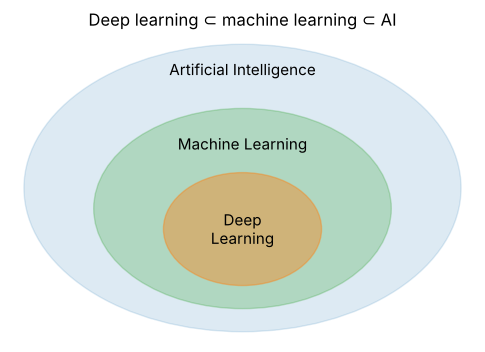

In [2]:
from matplotlib.patches import Ellipse

fig, ax = plt.subplots(figsize=(6, 4))
ax.set_xlim(0, 10); ax.set_ylim(0, 6); ax.axis('off')
ax.add_patch(Ellipse((5, 3.0), 9.4, 5.6, alpha=0.15, color='tab:blue'))
ax.add_patch(Ellipse((5, 2.6), 6.4, 3.9, alpha=0.25, color='tab:green'))
ax.add_patch(Ellipse((5, 2.2), 3.4, 2.2, alpha=0.40, color='tab:orange'))
ax.text(5, 5.2, 'Artificial Intelligence', ha='center', fontsize=11)
ax.text(5, 3.75, 'Machine Learning', ha='center', fontsize=11)
ax.text(5, 2.2, 'Deep\nLearning', ha='center', va='center', fontsize=11)
ax.set_title('Deep learning ⊂ machine learning ⊂ AI')
plt.savefig('outputs/ai_ml_dl_nested.png', dpi=110, bbox_inches='tight')
plt.show()

## 3. Why is it worth learning?

The chapter argues for learning deep learning. The main arguments, restated and expanded:

1. **It is broadly useful.** The same core machinery is used for images, speech, text,
   recommendations, games, and scientific data. Learning one set of ideas unlocks many application areas.
2. **The core is surprisingly small.** A working neural network that learns fits in a few dozen lines
   of NumPy. The field feels intimidating mostly because of vocabulary and scale, not because
   the central idea is deep mathematics. The prerequisites are modest (see §5).
3. **It transfers.** Once you understand weights, error, gradients and layers, every framework and
   every new architecture is a variation on things you already know.
4. **It makes you a better practitioner.** When training misbehaves (error not decreasing,
   exploding numbers, a model that memorises), you can only diagnose it if you understand what is
   happening inside.

## 4. Why build it from scratch with NumPy?

Frameworks such as PyTorch or TensorFlow compute gradients for you. That is wonderful for
productivity, but it hides the mechanism. The book therefore builds networks **by hand with NumPy**
first and only introduces frameworks later.

An analogy: you can drive a car without knowing how the engine works, but when it stalls on the
highway, the person who understands the engine fixes it faster. The same holds for training
neural networks. This repository follows the same philosophy — every chapter notebook
implements the idea with plain NumPy arrays and loops, then checks it numerically.

## 5. What you need to know first

| Topic | How much is needed | Where it shows up |
|---|---|---|
| Python (lists, loops, functions) | comfortable | everywhere |
| Basic linear algebra: vectors, dot product, matrix–vector product | the idea, recalled as we go | Chapter 3 onward |
| Calculus: derivative as *slope* | intuition only | Chapter 4 onward |
| Statistics / probability | very little at first | later chapters |

Nothing here requires advanced mathematics; each concept is re-introduced right where it is first used.

## 6. Mental model 1 — machines that learn their own rules

*(Demo added by me; not from the book.)*

Classical programming: **rules + data → answers**. You write the rule.
Machine learning: **data + answers → rules**. The machine finds the rule.

Take converting Celsius to Fahrenheit. A programmer knows the rule: $F = \frac{9}{5}C + 32$.
Now pretend we *don't* know it, and only have slightly noisy example measurements. A learning
procedure can recover a rule that works almost as well. (`np.polyfit` is a closed-form shortcut and
**not** how neural networks learn; it just illustrates the *goal*: find the numbers
in the formula from examples. Chapter 4 shows the iterative way networks do it.)

learned rule : F = 1.802 * C + 31.948
true rule    : F = 1.800 * C + 32.000


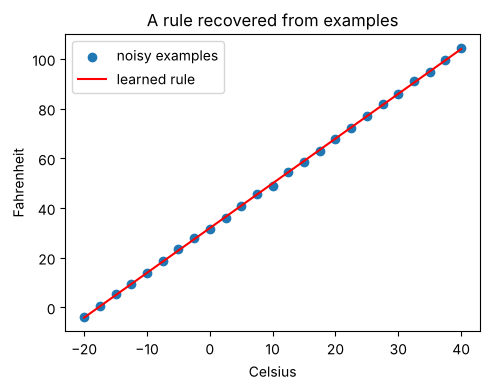

In [3]:
def celsius_to_fahrenheit_rule(c):
    # rule written by a programmer
    return c * 9 / 5 + 32

rng = np.random.default_rng(0)
celsius = np.linspace(-20, 40, 25)
fahrenheit = celsius_to_fahrenheit_rule(celsius) + rng.normal(0, 0.5, size=celsius.size)  # noisy examples

slope, intercept = np.polyfit(celsius, fahrenheit, deg=1)   # "learn" slope and intercept from examples
print(f"learned rule : F = {slope:.3f} * C + {intercept:.3f}")
print(f"true rule    : F = {9/5:.3f} * C + {32:.3f}")

plt.figure(figsize=(5, 4))
plt.scatter(celsius, fahrenheit, label='noisy examples')
plt.plot(celsius, slope * celsius + intercept, color='red', label='learned rule')
plt.xlabel('Celsius'); plt.ylabel('Fahrenheit'); plt.legend()
plt.title('A rule recovered from examples')
plt.tight_layout()
plt.savefig('outputs/learned_rule.png', dpi=110)
plt.show()

**Reading the output.** The learned slope and intercept land very close to 1.8 and 32 although we
never told the program the formula. The "knowledge" ended up stored in two numbers. A neural network
does the same thing with thousands or millions of numbers.

## 7. Mental model 2 — knobs and error

*(Demo added by me; not from the book.)*

Picture a machine with a **knob** (a weight $w$). The machine multiplies its input by the knob
setting to make a prediction: $\hat{y} = w \cdot x$. Learning means finding the knob setting
that makes predictions match the known answers, which we measure with an **error** — here the
mean squared error (MSE):

$$E(w) = \frac{1}{N}\sum_{i=1}^{N}\left(w\,x_i - y_i\right)^2$$

Below we simply try many knob positions and look at the error of each one. Good settings sit at
the bottom of a valley. Chapter 4 replaces this brute-force search with *gradient descent*,
which walks downhill directly.

best knob setting found by brute force: w = 2.00  (error = 0.0250)


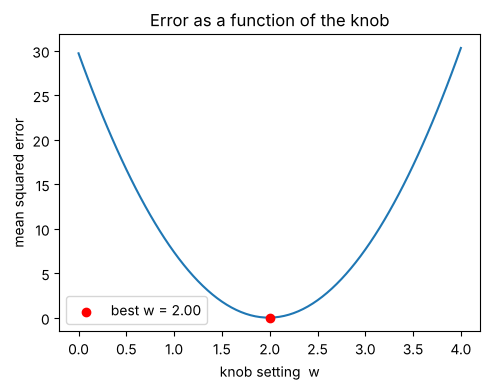

In [4]:
x = np.array([1.0, 2.0, 3.0, 4.0])
y = np.array([2.1, 3.9, 6.2, 7.8])          # roughly y = 2x

candidate_w = np.linspace(0, 4, 81)
errors = np.array([np.mean((w * x - y) ** 2) for w in candidate_w])
best_w = candidate_w[np.argmin(errors)]
print(f"best knob setting found by brute force: w = {best_w:.2f}  (error = {errors.min():.4f})")

plt.figure(figsize=(5, 4))
plt.plot(candidate_w, errors)
plt.scatter([best_w], [errors.min()], color='red', zorder=3, label=f'best w = {best_w:.2f}')
plt.xlabel('knob setting  w'); plt.ylabel('mean squared error')
plt.title('Error as a function of the knob')
plt.legend(); plt.tight_layout()
plt.savefig('outputs/knob_error_curve.png', dpi=110)
plt.show()

**Reading the output.** The error curve is a smooth valley (a parabola) with its lowest point near
$w\approx 2$, the slope of the underlying trend. This picture — *error as a landscape over the weights* —
is the central image of deep learning. Training = moving downhill in that landscape.

## 8. Roadmap of Chapters 1–6

| Chapter | Topic | Core question |
|---|---|---|
| 1 | Introducing deep learning | Why learn it, and how will we learn it? |
| 2 | Fundamental concepts | What does "a machine learns" mean? Supervised vs unsupervised, parametric vs non-parametric |
| 3 | Forward propagation | How does a network turn inputs into a prediction? |
| 4 | Gradient descent | How does a network use its error to improve? |
| 5 | Learning multiple weights | How does learning scale to many inputs and outputs? |
| 6 | Backpropagation | How do we train networks with hidden layers? |

## Summary

- Deep learning = many-layered neural networks whose weights are **learned from data**.
- It is a subset of machine learning, which is a subset of AI.
- The core idea is small and learnable: *prediction → error → adjust weights*.
- We build it from scratch in NumPy so that nothing is a black box.
- Mental models to carry forward: **data + answers → rules**, and **learning = moving downhill on an error landscape**.